# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) nous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh`, `heures_courant` |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type`, `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |
| `donnees/consommation.csv` | quartier et mois | fichier de référence (question 8) |

Plan : diagnostic, nettoyage, jointures, une partie par question (4 à 8), puis la conclusion.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
DOSSIER = Path("donnees")
assert DOSSIER.exists(), "Lancez le notebook depuis le dossier du dépôt."

## 1. Diagnostic

On décrit les données **avant** de les toucher, et on note chaque problème.

**1.** Forme, types, valeurs manquantes et lignes en double de `consommation_brut.csv`.

Attendu : `(300, 4)` ; `kwh` est du texte ; 9 manquants dans `kwh` ; 12 lignes en double.

In [2]:
brut = pd.read_csv(DOSSIER / "consommation_brut.csv")

print("Forme :", brut.shape)
print("\nTypes :")
print(brut.dtypes)
print("\nValeurs manquantes :")
print(brut.isna().sum())
print("\nLignes en double :", brut.duplicated().sum())

Forme : (300, 4)

Types :
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

Valeurs manquantes :
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

Lignes en double : 12


**Constat :** 300 lignes au lieu de 288 (12 quartiers × 24 mois) : il y a des doublons. `kwh` n'est pas numérique, donc on ne peut pas encore faire de calculs dessus.

**2.** Combien d'écritures différentes pour `quartier` ?

Attendu : 43.

In [3]:
print("Écritures différentes :", brut["quartier"].nunique())
print(sorted(brut["quartier"].unique()))

Écritures différentes : 43
[' Bas-Peu-de-Chose', ' Carénage', ' Delmas 33', ' Delmas 65', ' Delmas 75', ' Morne Calvaire', ' Petite-Anse', ' Place Saint-Pierre', ' Thomassin', 'BAS-PEU-DE-CHOSE', 'BOIS-VERNA', 'Bas-Peu-de-Chose', 'Bas-Peu-de-Chose ', 'Bois-Verna', 'CARÉNAGE', 'CENTRE-VILLE', 'Carénage', 'Carénage ', 'Centre-ville', 'Centre-ville ', 'DELMAS 33', 'Delmas 33', 'Delmas 33 ', 'Delmas 65', 'Delmas 75', 'Delmas 75 ', 'Morne Calvaire', 'PLACE SAINT-PIERRE', 'Petite-Anse', 'Place Saint-Pierre', 'Place Saint-Pierre ', 'RUE 15', 'Rue 15', 'Rue 15 ', 'THOMASSIN', 'Thomassin', 'Thomassin ', 'bas-peu-de-chose', 'carénage', 'centre-ville', 'delmas 65', 'delmas 75', 'place saint-pierre']


**Constat :** 43 écritures pour 12 quartiers : majuscules différentes (`BOIS-VERNA`, `bois-verna`) et espaces en trop au début ou à la fin (`" Thomassin"`, `"Rue 15 "`).

**3.** Pourquoi `kwh` n'est-il pas un nombre ? On affiche les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir, sans compter les vrais manquants.

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [4]:
converti = pd.to_numeric(brut["kwh"], errors="coerce")
illisibles = brut.loc[brut["kwh"].notna() & converti.isna(), "kwh"]
print("Valeurs non convertibles :", len(illisibles))
print(illisibles.head(15).tolist())

Valeurs non convertibles : 52
['184410 kWh', '206280 kWh', '215140 kWh', '251 900', '274520 kWh', '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh', '299610 kWh', '373 880', '333670 kWh', '597730 kWh', '456060 kWh']


**Constat :** deux formats gênent la conversion : l'unité « kWh » collée au nombre, et un espace comme séparateur de milliers.

**Problèmes à corriger :** `kwh` en texte, des noms de quartiers incohérents, 12 doublons, 9 `kwh` manquants et, on le verra, 4 relevés saisis 10 fois trop grands.

## 2. Nettoyage

On travaille sur une copie `propre`, une cellule par problème.

**4.** Convertir `kwh` en nombre : retirer « kWh » et les espaces, puis `pd.to_numeric`.

Attendu : 9 manquants, les vrais.

In [5]:
propre = brut.copy()
propre["kwh"] = (
    propre["kwh"]
    .str.replace("kWh", "", regex=False)
    .str.replace(" ", "", regex=False)
)
propre["kwh"] = pd.to_numeric(propre["kwh"])

print("Manquants dans kwh :", propre["kwh"].isna().sum())
assert propre["kwh"].isna().sum() == 9

Manquants dans kwh : 9


**5.** Harmoniser les quartiers avec les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules (`.str.title()` abîmerait « Bas-Peu-de-Chose »).

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [6]:
quartiers = pd.read_csv(DOSSIER / "quartiers.csv")
officiels = {nom.lower(): nom for nom in quartiers["quartier"]}

propre["quartier"] = propre["quartier"].str.strip().str.lower().map(officiels)

print("Noms perdus par map :", propre["quartier"].isna().sum())
print("Quartiers distincts :", propre["quartier"].nunique())
assert propre["quartier"].isna().sum() == 0
assert propre["quartier"].nunique() == 12

Noms perdus par map : 0
Quartiers distincts : 12


**6.** Supprimer les doublons (maintenant que les noms sont harmonisés), puis les lignes sans `kwh`.

Attendu : `(279, 4)`.

In [7]:
avant = len(propre)
propre = propre.drop_duplicates()
print("Doublons supprimés :", avant - len(propre))

avant = len(propre)
propre = propre.dropna(subset=["kwh"])
print("Lignes sans kwh supprimées :", avant - len(propre))

propre["kwh"] = propre["kwh"].astype("int64")
print("Forme :", propre.shape)
assert propre.shape == (279, 4)

Doublons supprimés : 12
Lignes sans kwh supprimées : 9
Forme : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Règle : plus de 3 fois la médiane de son quartier, on divise par 10.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [8]:
mediane = propre.groupby("quartier")["kwh"].transform("median")
aberrant = propre["kwh"] > 3 * mediane

print("Relevés aberrants :")
print(propre.loc[aberrant, ["mois", "quartier", "kwh"]])

propre.loc[aberrant, "kwh"] = propre.loc[aberrant, "kwh"] // 10
print("\nMaximum de kwh après correction :", propre["kwh"].max())
assert aberrant.sum() == 4
assert propre["kwh"].max() == 742780

Relevés aberrants :
        mois        quartier      kwh
90   2025-02       Delmas 33  3602600
140  2025-02       Delmas 75  2012700
200  2024-02  Morne Calvaire  1439200
251  2024-01          Rue 15   997700

Maximum de kwh après correction : 742780


**Pourquoi la médiane du quartier ?** Un quartier commercial consomme naturellement plus qu'un quartier résidentiel : on compare chaque relevé à son propre quartier. Et la médiane n'est presque pas tirée vers le haut par les valeurs aberrantes, contrairement à la moyenne.

**8.** La preuve : on compare `propre` à `consommation.csv` sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [9]:
reference = pd.read_csv(DOSSIER / "consommation.csv")
colonnes = ["mois", "quartier", "kwh", "heures_courant"]
cles = ["mois", "quartier"]

ref_communes = reference.merge(propre[cles], on=cles, how="inner")

a = propre[colonnes].sort_values(cles).reset_index(drop=True)
b = ref_communes[colonnes].sort_values(cles).reset_index(drop=True)

print("Lignes de la référence :", len(reference))
print("Lignes comparées :", len(a), len(b))
print("Identiques :", a.equals(b))
assert a.equals(b)

Lignes de la référence : 288
Lignes comparées : 279 279
Identiques : True


## 3. Jointures

On compte les lignes avant et après chaque `merge` : une jointure ne doit ni perdre ni dupliquer de relevés.

**9.** Joindre `quartiers`, puis ajouter `kwh_par_abonne` (arrondi à 1 décimale) et `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [10]:
print("Avant :", len(propre))
df = propre.merge(quartiers, on="quartier", how="left", validate="many_to_one")
print("Après :", len(df))

df["kwh_par_abonne"] = (df["kwh"] / df["abonnes"]).round(1)
df["annee"] = df["mois"].str[:4].astype(int)

exemple = df.query("quartier == 'Bas-Peu-de-Chose' and mois == '2024-01'")["kwh_par_abonne"].iloc[0]
print("Bas-Peu-de-Chose, 2024-01 :", exemple)
assert len(df) == 279 and df["commune"].notna().all()
assert exemple == 85.8

Avant : 279
Après : 279
Bas-Peu-de-Chose, 2024-01 : 85.8


**10.** Joindre la météo. La clé est double : `mois` **et** `commune`.

Attendu : 279 lignes avant et après, aucune température manquante.

In [11]:
meteo = pd.read_csv(DOSSIER / "meteo.csv")

print("Avant :", len(df))
df = df.merge(meteo, on=["mois", "commune"], how="left", validate="many_to_one")
print("Après :", len(df))
print("Températures manquantes :", df["temperature_c"].isna().sum())
assert len(df) == 279 and df["temperature_c"].notna().all()
print(df.head())

Avant : 279
Après : 279
Températures manquantes : 0
      mois          quartier     kwh  ...  annee temperature_c pluie_mm
0  2024-01  Bas-Peu-de-Chose  184410  ...   2024          25.7       33
1  2024-02  Bas-Peu-de-Chose  195930  ...   2024          25.5       40
2  2024-03  Bas-Peu-de-Chose  186560  ...   2024          27.2       99
3  2024-04  Bas-Peu-de-Chose  236730  ...   2024          27.4      119
4  2024-05  Bas-Peu-de-Chose  206280  ...   2024          28.1      185

[5 rows x 11 columns]


**11.** Enregistrer le fichier propre, sans index. C'est ce fichier que lit `app.py`.

Attendu : `(279, 11)`.

In [12]:
df.to_csv(DOSSIER / "consommation_propre.csv", index=False)

relu = pd.read_csv(DOSSIER / "consommation_propre.csv")
print("Forme relue :", relu.shape)
print(relu.columns.tolist())
assert relu.shape == (279, 11)

Forme relue : (279, 11)
['mois', 'quartier', 'kwh', 'heures_courant', 'commune', 'type', 'abonnes', 'kwh_par_abonne', 'annee', 'temperature_c', 'pluie_mm']


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64
          quartier        type  kwh_par_abonne
      Centre-ville  Commercial           468.7
Place Saint-Pierre  Commercial           458.3
         Delmas 33  Commercial           374.4
            Rue 15  Commercial           268.5
    Morne Calvaire Résidentiel           166.1
         Thomassin Résidentiel           146.0
         Delmas 65 Résidentiel           134.9
        Bois-Verna Résidentiel           130.1
         Delmas 75 Résidentiel           118.6
  Bas-Peu-de-Chose Résidentiel           100.2
          Carénage Résidentiel            72.2
       Petite-Anse Résidentiel            69.6


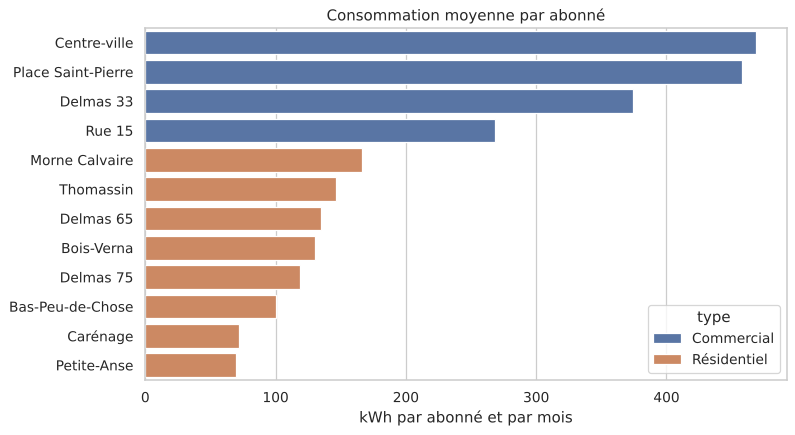

In [13]:
par_type = df.groupby("type")["kwh_par_abonne"].mean().round(1)
print(par_type)

classement = (
    df.groupby(["quartier", "type"], as_index=False)["kwh_par_abonne"]
    .mean()
    .sort_values("kwh_par_abonne", ascending=False)
)
print(classement.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=classement, x="kwh_par_abonne", y="quartier", hue="type", dodge=False, ax=ax)
ax.set(title="Consommation moyenne par abonné", xlabel="kWh par abonné et par mois", ylabel="")
plt.tight_layout()
plt.show()

**Interprétation :** un abonné d'un quartier commercial consomme en moyenne **393,2 kWh par mois**, contre **117,4** en résidentiel, soit environ 3,3 fois plus. Les trois premiers sont commerciaux : Centre-ville (468,7), Place Saint-Pierre (458,3) et Delmas 33 (374,4). En bas du classement, deux quartiers résidentiels de Cap-Haïtien : Carénage (72,2) et Petite-Anse (69,6).

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé de la consommation totale par commune et par année, la hausse en % (calculée avant d'arrondir), les totaux en millions de kWh arrondis à 2. Puis la courbe mensuelle de la consommation par abonné pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

annee            2024   2025  hausse_%
commune                               
Cap-Haïtien      4.59   5.62      22.5
Pétion-Ville     8.60   9.68      12.6
Port-au-Prince  10.09  10.31       2.3
Delmas          11.61  11.74       1.1


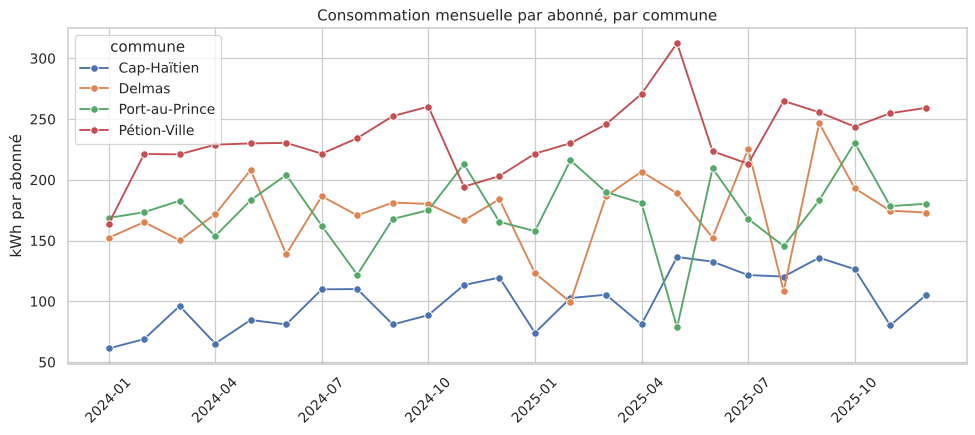

In [14]:
totaux = df.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")
totaux["hausse_%"] = (totaux[2025] - totaux[2024]) / totaux[2024] * 100
totaux[2024] = (totaux[2024] / 1e6).round(2)
totaux[2025] = (totaux[2025] / 1e6).round(2)
totaux = totaux.sort_values("hausse_%", ascending=False)
totaux["hausse_%"] = totaux["hausse_%"].round(1)
print(totaux)

abonnes_commune = quartiers.groupby("commune")["abonnes"].sum()
mensuel = df.groupby(["commune", "mois"], as_index=False)["kwh"].sum()
mensuel["kwh_par_abonne"] = mensuel["kwh"] / mensuel["commune"].map(abonnes_commune)

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=mensuel, x="mois", y="kwh_par_abonne", hue="commune", marker="o", ax=ax)
ax.set(title="Consommation mensuelle par abonné, par commune", xlabel="", ylabel="kWh par abonné")
ax.set_xticks(ax.get_xticks()[::3])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interprétation :** Cap-Haïtien connaît la plus forte hausse, de **4,59 à 5,62 millions de kWh** (+22,5 % ; 22,46 % avant arrondi). Pétion-Ville suit (+12,6 %), puis Port-au-Prince (+2,3 %). Delmas reste la commune qui consomme le plus en total (11,74 millions en 2025), mais c'est elle qui progresse le moins (**+1,1 %**). Les courbes mensuelles montrent de fortes variations d'un mois à l'autre dans les quatre communes.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points heures de courant / consommation par abonné, puis les deux corrélations.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

Relevés résidentiels : 186
Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


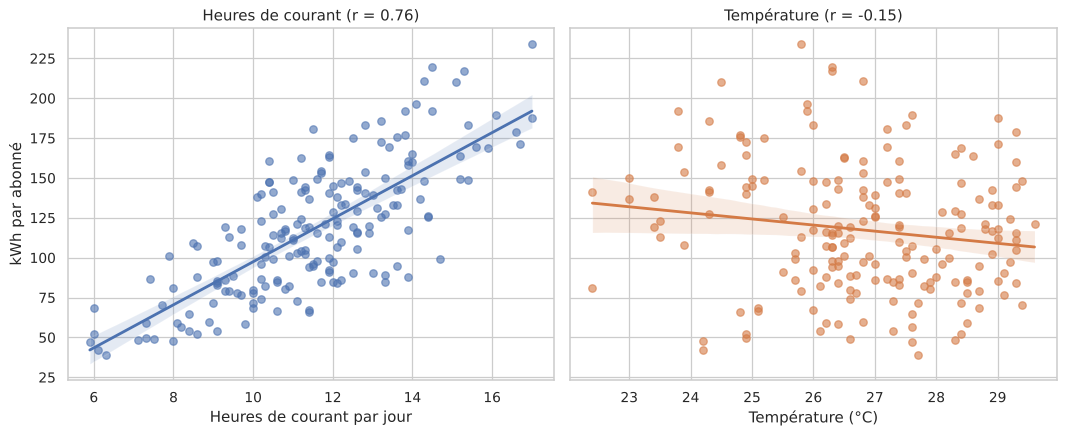

In [15]:
residentiel = df[df["type"] == "Résidentiel"]

corr_heures = residentiel["kwh_par_abonne"].corr(residentiel["heures_courant"])
corr_temp = residentiel["kwh_par_abonne"].corr(residentiel["temperature_c"])
print("Relevés résidentiels :", len(residentiel))
print(f"Corrélation avec les heures de courant : {corr_heures:.2f}")
print(f"Corrélation avec la température : {corr_temp:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
sns.regplot(data=residentiel, x="heures_courant", y="kwh_par_abonne", ax=axes[0], scatter_kws={"alpha": 0.6})
axes[0].set(title=f"Heures de courant (r = {corr_heures:.2f})", xlabel="Heures de courant par jour", ylabel="kWh par abonné")
sns.regplot(data=residentiel, x="temperature_c", y="kwh_par_abonne", ax=axes[1], color="#d47a45", scatter_kws={"alpha": 0.6})
axes[1].set(title=f"Température (r = {corr_temp:.2f})", xlabel="Température (°C)", ylabel="")
plt.tight_layout()
plt.show()

**Interprétation :** sur les **186 relevés résidentiels**, la consommation par abonné est fortement liée aux heures de courant (**r = 0,76**) : quand le courant est disponible plus longtemps, on consomme plus. Le lien avec la température est faible et même légèrement négatif (**r = -0,15**). Autrement dit, la consommation suit surtout l'offre d'électricité, pas la chaleur. On se limite aux quartiers résidentiels pour ne pas mélanger des quartiers commerciaux, dont le niveau de consommation est très différent.

## 7. Où les coupures sont-elles les plus longues ?

**15.** Heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

                  Q1  médiane    Q3
commune                            
Cap-Haïtien      8.3     10.0  11.7
Delmas          10.1     11.9  13.0
Port-au-Prince  10.7     11.6  13.1
Pétion-Ville    10.4     11.6  13.0

Relevés 2025 sous 8 h : 3
   mois  quartier  heures_courant
2025-01 Delmas 33             7.4
2025-08  Carénage             7.3
2025-11    Rue 15             5.9


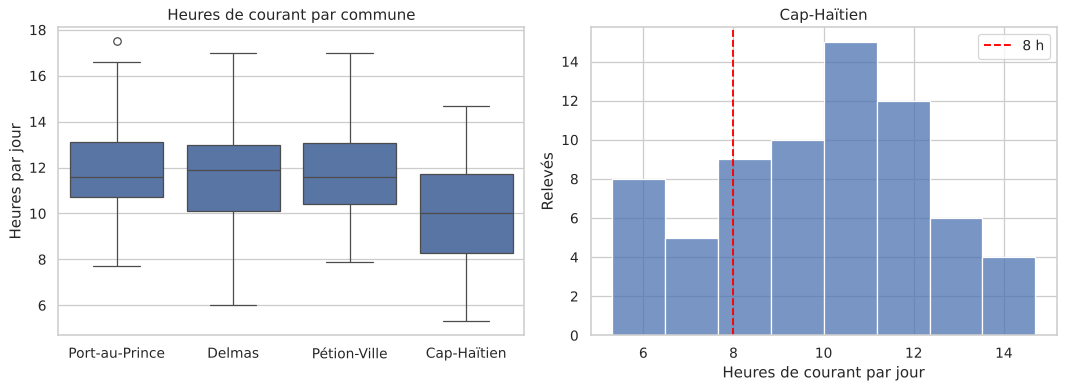

In [16]:
resume = df.groupby("commune")["heures_courant"].quantile([0.25, 0.5, 0.75]).unstack()
resume.columns = ["Q1", "médiane", "Q3"]
print(resume.round(1))

moins_8h = df[(df["annee"] == 2025) & (df["heures_courant"] < 8)]
print("\nRelevés 2025 sous 8 h :", len(moins_8h))
print(moins_8h[["mois", "quartier", "heures_courant"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="commune", y="heures_courant", ax=axes[0])
axes[0].set(title="Heures de courant par commune", xlabel="", ylabel="Heures par jour")
cap = df[df["commune"] == "Cap-Haïtien"]
sns.histplot(cap["heures_courant"], bins=8, ax=axes[1])
axes[1].axvline(8, color="red", linestyle="--", label="8 h")
axes[1].set(title="Cap-Haïtien", xlabel="Heures de courant par jour", ylabel="Relevés")
axes[1].legend()
plt.tight_layout()
plt.show()

**Interprétation :** Cap-Haïtien a le moins de courant, avec une médiane de **10,0 heures par jour** (Q1 = 8,3 ; Q3 = 11,7), contre 11,6 à 11,9 heures dans les trois autres communes. En 2025, **3 relevés** passent sous 8 heures par jour : Delmas 33 en janvier (7,4 h), Carénage en août (7,3 h) et Rue 15 en novembre (5,9 h).

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations du fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

   mois     quartier       type    kwh
2025-07    Delmas 33 Commercial 742780
2024-11 Centre-ville Commercial 597730
2025-09    Delmas 33 Commercial 591420


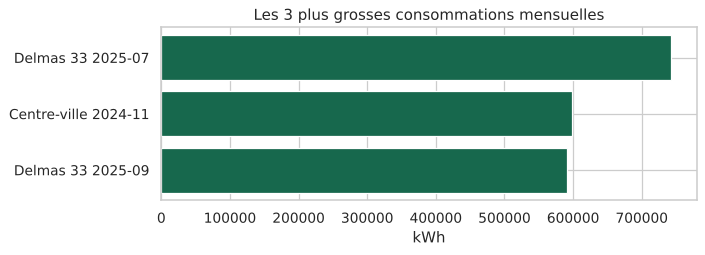

In [17]:
top3 = df.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]
print(top3.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3))
etiquettes = top3["quartier"] + " " + top3["mois"]
ax.barh(etiquettes, top3["kwh"], color="#17684d")
ax.invert_yaxis()
ax.set(title="Les 3 plus grosses consommations mensuelles", xlabel="kWh")
plt.tight_layout()
plt.show()

**Interprétation :** les trois plus gros relevés sont tous dans des quartiers commerciaux : Delmas 33 en juillet 2025 (**742 780 kWh**), Centre-ville en novembre 2024 (597 730) et Delmas 33 en septembre 2025 (591 420). Ces deux mois de Delmas 33 ont aussi beaucoup d'heures de courant (16,9 h et 14,8 h), ce qui va dans le sens de la partie 6.

## 9. Conclusion

La consommation suit les heures de courant, pas la chaleur : dans les quartiers résidentiels, la corrélation est de 0,76 avec les heures de courant et de -0,15 avec la température. Une corrélation montre un lien, pas une cause.